# Compare SVM, k-NN, and Decision Tree models by manually computing and visualizing performance metrics such as accuracy, precision, recall, and decision boundaries, ensuring a deep analysis of model trade-offs and real-world applicability.

Dataset shape: (918, 12)
Classes: [0, 1]
Training rows: 735
Testing rows: 183
SVM training completed
k-NN training completed
Decision Tree training completed

--- Manual Model Comparison ---
               Accuracy  Precision  Recall  Specificity  F1-score
SVM              0.8142     0.8018  0.8812       0.7317    0.8396
k-NN             0.8251     0.8165  0.8812       0.7561    0.8476
Decision Tree    0.8251     0.8000  0.9109       0.7195    0.8519


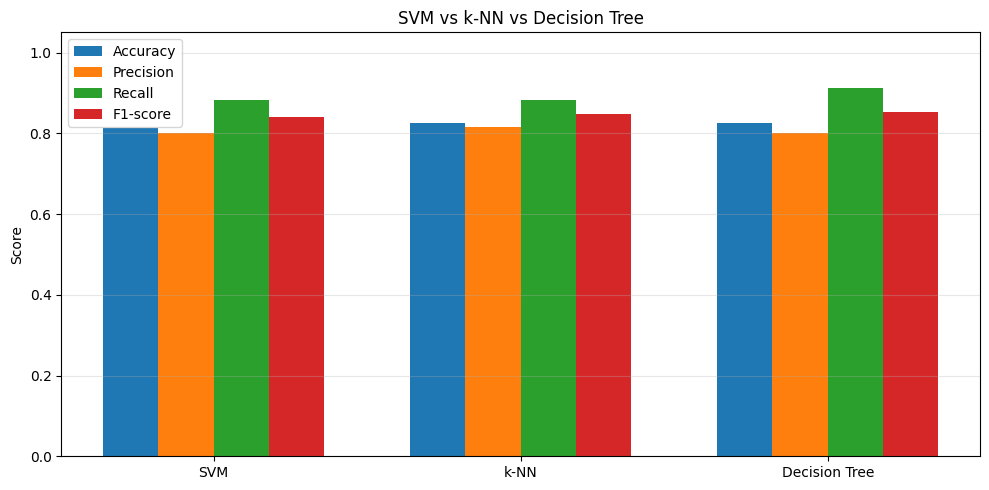

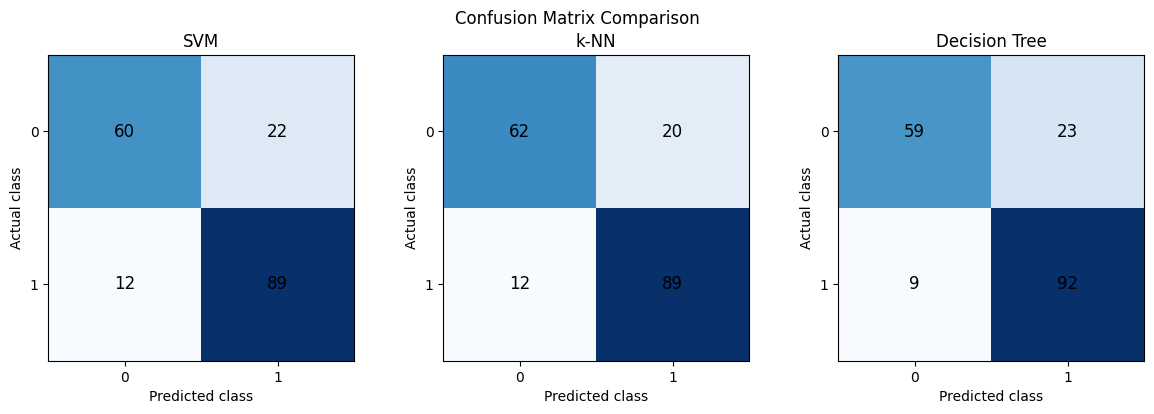

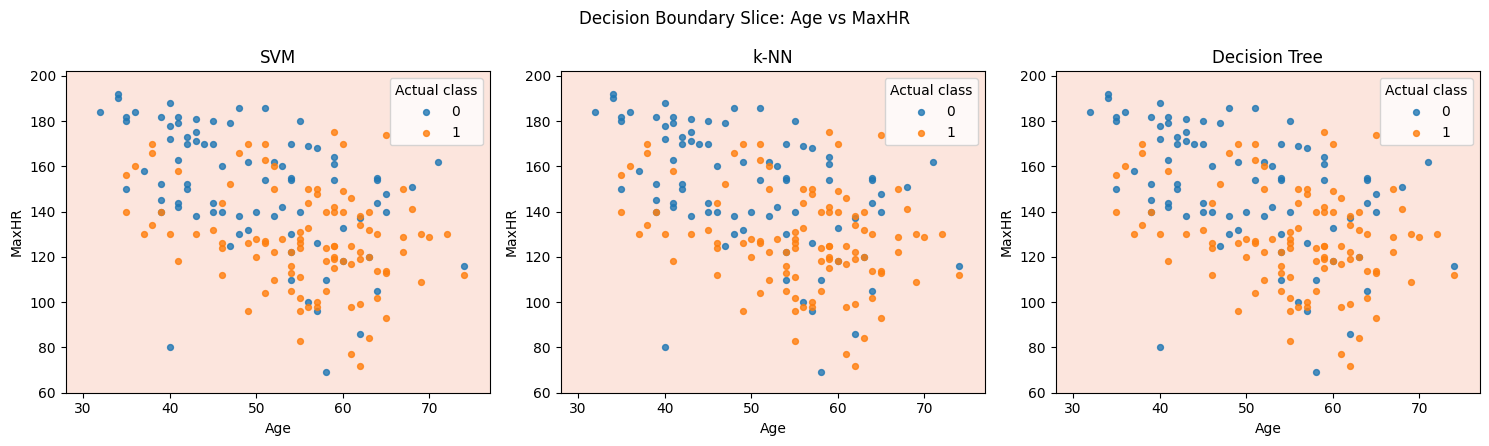


--- Decision Tree Rules ---
IF ST_Slope_Up <= 0.128
  IF ChestPainType_ASY <= -0.045
    IF Sex_F <= 0.651
      IF MaxHR <= -0.239
        IF RestingBP <= -0.105
          Predict: 1
        ELSE (RestingBP > -0.105)
          Predict: 1
      ELSE (MaxHR > -0.239)
        IF ST_Slope_Flat <= 0.004
          Predict: 0
        ELSE (ST_Slope_Flat > 0.004)
          Predict: 1
    ELSE (Sex_F > 0.651)
      IF ExerciseAngina_N <= -0.195
        Predict: 1
      ELSE (ExerciseAngina_N > -0.195)
        IF FastingBS <= 0.598
          Predict: 0
        ELSE (FastingBS > 0.598)
          Predict: 1
  ELSE (ChestPainType_ASY > -0.045)
    IF Sex_F <= 0.651
      IF RestingBP <= -2.401
        Predict: 0
      ELSE (RestingBP > -2.401)
        IF Age <= 2.224
          Predict: 1
        ELSE (Age > 2.224)
          Predict: 1
    ELSE (Sex_F > 0.651)
      IF FastingBS <= 0.598
        IF RestingBP <= 0.455
          Predict: 0
        ELSE (RestingBP > 0.455)
          Predict: 1
      

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier


# 1. Load dataset
df = pd.read_csv("heart.csv")
df = df.dropna(subset=["HeartDisease"]).reset_index(drop=True)

X = df.drop(columns=["HeartDisease"])
y, class_names = pd.factorize(df["HeartDisease"], sort=True)

if len(class_names) != 2:
    raise ValueError("Aa code binary HeartDisease classification mate chhe.")

print("Dataset shape:", df.shape)
print("Classes:", list(class_names))


# 2. Manual stratified 80-20 split
rng = np.random.default_rng(42)
train_idx, test_idx = [], []

for label in np.unique(y):
    idx = np.where(y == label)[0]
    rng.shuffle(idx)

    n_test = max(1, int(len(idx) * 0.20))
    n_test = min(n_test, len(idx) - 1)

    test_idx.extend(idx[:n_test])
    train_idx.extend(idx[n_test:])

train_idx = np.array(train_idx, dtype=int)
test_idx = np.array(test_idx, dtype=int)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train, y_test = y[train_idx], y[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# 3. Handle missing values
num_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

cat_cols = [
    col for col in X_train.columns
    if col not in num_cols
]

for col in num_cols:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

    median = X_train[col].median()
    if pd.isna(median):
        median = 0

    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

for col in cat_cols:
    mode = X_train[col].mode(dropna=True)
    fill = mode.iloc[0] if not mode.empty else "Unknown"

    X_train[col] = X_train[col].fillna(fill).astype(str)
    X_test[col] = X_test[col].fillna(fill).astype(str)


# 4. Encode categorical columns
X_train_df = pd.get_dummies(
    X_train, columns=cat_cols, dtype=float
)

X_test_df = pd.get_dummies(
    X_test, columns=cat_cols, dtype=float
)

X_test_df = X_test_df.reindex(
    columns=X_train_df.columns, fill_value=0
)

feature_names = X_train_df.columns

A = X_train_df.to_numpy(dtype=float)
B = X_test_df.to_numpy(dtype=float)


# 5. Standardize features using training data
mean = A.mean(axis=0)
std = A.std(axis=0)
std[std == 0] = 1

A_scaled = (A - mean) / std
B_scaled = (B - mean) / std


# 6. Create three models
models = {
    "SVM": SVC(
        kernel="rbf",
        C=1.0
    ),

    "k-NN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        random_state=42
    )
}


# 7. Train models and predict
predictions = {}

for name, model in models.items():
    model.fit(A_scaled, y_train)
    predictions[name] = model.predict(B_scaled)

    print(name, "training completed")


# 8. Manually calculate metrics
def manual_evaluation(y_true, y_pred):
    # Rows = actual class, columns = predicted class
    cm = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        cm[int(actual), int(predicted)] += 1

    tn, fp = cm[0, 0], cm[0, 1]
    fn, tp = cm[1, 0], cm[1, 1]

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    specificity = tn / (tn + fp) if tn + fp else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1-score": f1
    }, cm


results = {}
confusion_matrices = {}

for name, pred in predictions.items():
    results[name], confusion_matrices[name] = (
        manual_evaluation(y_test, pred)
    )

results_df = pd.DataFrame(results).T

print("\n--- Manual Model Comparison ---")
print(results_df.round(4).to_string())


# 9. Plot performance metrics
metrics_to_plot = [
    "Accuracy", "Precision", "Recall", "F1-score"
]

x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(10, 5))

for i, metric in enumerate(metrics_to_plot):
    values = results_df[metric].values

    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=metric
    )

plt.xticks(x, results_df.index)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("SVM vs k-NN vs Decision Tree")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# 10. Plot confusion matrices manually
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    ax.imshow(cm, cmap="Blues")

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                fontsize=12
            )

    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks([0, 1], labels=[str(c) for c in class_names])
    ax.set_yticks([0, 1], labels=[str(c) for c in class_names])

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()


# 11. Visualize decision boundaries using Age and MaxHR
# The trained models use all features. This graph shows a
# 2D slice while holding other features at one training example.

if "Age" not in feature_names or "MaxHR" not in feature_names:
    print("Age or MaxHR feature not found; boundary plots skipped.")

else:
    age_idx = feature_names.get_loc("Age")
    hr_idx = feature_names.get_loc("MaxHR")

    ages = np.linspace(
        X_train_df["Age"].min(),
        X_train_df["Age"].max(),
        70
    )

    maxhrs = np.linspace(
        X_train_df["MaxHR"].min(),
        X_train_df["MaxHR"].max(),
        70
    )

    xx, yy = np.meshgrid(ages, maxhrs)

    # Choose a real training row near the standardized average
    baseline_idx = np.argmin(np.sum(A_scaled ** 2, axis=1))
    baseline = A_scaled[baseline_idx].copy()

    grid = np.tile(baseline, (xx.size, 1))

    grid[:, age_idx] = (xx.ravel() - mean[age_idx]) / std[age_idx]
    grid[:, hr_idx] = (yy.ravel() - mean[hr_idx]) / std[hr_idx]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    for ax, (name, model) in zip(axes, models.items()):
        boundary = model.predict(grid).reshape(xx.shape)

        ax.contourf(
            xx, yy, boundary,
            levels=[-0.5, 0.5, 1.5],
            alpha=0.25,
            cmap="coolwarm"
        )

        # Show test examples in original Age/MaxHR values
        for class_id in [0, 1]:
            mask = y_test == class_id

            ax.scatter(
                X_test_df.loc[mask, "Age"],
                X_test_df.loc[mask, "MaxHR"],
                label=str(class_names[class_id]),
                s=18,
                alpha=0.8
            )

        ax.set_title(name)
        ax.set_xlabel("Age")
        ax.set_ylabel("MaxHR")
        ax.legend(title="Actual class")

    plt.suptitle("Decision Boundary Slice: Age vs MaxHR")
    plt.tight_layout()
    plt.show()


# 12. Show feature decision paths for Decision Tree
tree = models["Decision Tree"]

print("\n--- Decision Tree Rules ---")

def show_rules(node=0, depth=0):
    indent = "  " * depth

    if tree.tree_.feature[node] == -2:
        counts = tree.tree_.value[node][0]
        predicted_class = class_names[np.argmax(counts)]

        print(indent + "Predict:", predicted_class)
        return

    feature_id = tree.tree_.feature[node]
    feature = feature_names[feature_id]
    threshold = tree.tree_.threshold[node]

    print(f"{indent}IF {feature} <= {threshold:.3f}")

    show_rules(tree.tree_.children_left[node], depth + 1)

    print(f"{indent}ELSE ({feature} > {threshold:.3f})")

    show_rules(tree.tree_.children_right[node], depth + 1)


show_rules()


# 13. Identify best model for each metric
print("\n--- Best Model by Metric ---")

for metric in metrics_to_plot:
    best_name = results_df[metric].idxmax()
    best_score = results_df.loc[best_name, metric]

    print(f"{metric}: {best_name} ({best_score:.4f})")